In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, cross_val_score, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

low_conc_thresh = 3
# Load in original data and separate out x and y
# Briefly converting this to just classify WT, Beta, and Delta
combined_augmented_data = pd.read_csv("Embedded_FS/combined_augmented_data.csv")
# combined_augmented_data = combined_augmented_data[combined_augmented_data['target_vector'] != 'Omicron']
aug_colnames = combined_augmented_data.columns
augmented_x = combined_augmented_data[aug_colnames[3:len(aug_colnames)]]
augmented_y = combined_augmented_data['target_vector']

# Create dataset with only conc values between 0.1 and 100 - this is sort of a baseline data set where I remove some of the "gimme" observations at high concentrations
# and don't quite remove all the low concentration values. I really don't think there's any signal below 
medium_trimmed_augmented_data = combined_augmented_data[(combined_augmented_data['Conc.']<251) & (combined_augmented_data['Conc.']>low_conc_thresh)]
medium_trimmed_x = medium_trimmed_augmented_data[aug_colnames[3:len(aug_colnames)]]
medium_trimmed_y = medium_trimmed_augmented_data['target_vector']

low_trimmed_augmented_data = combined_augmented_data[(combined_augmented_data['Conc.']<10) & (combined_augmented_data['Conc.']>0.01)]
low_trimmed_x = low_trimmed_augmented_data[aug_colnames[3:len(aug_colnames)]]
low_trimmed_y = low_trimmed_augmented_data['target_vector']

combined_augmented_data_total_norm = pd.read_csv("Embedded_FS/fluorescence_normalized_by_total.csv")
cab_cols = [col for col in combined_augmented_data_total_norm if col.startswith('cAb')]
cab_cols.append('total_fluorescence')
cab_cols.append('average_fluorescence')
aug_total_norm_x = combined_augmented_data_total_norm[cab_cols]
aug_total_norm_y = combined_augmented_data_total_norm['target_vector']

trim_aug_total_norm_x = aug_total_norm_x[(combined_augmented_data_total_norm['Conc.']<251) & (combined_augmented_data_total_norm['Conc.']>low_conc_thresh)]
trim_aug_total_norm_y = aug_total_norm_y[(combined_augmented_data_total_norm['Conc.']<251) & (combined_augmented_data_total_norm['Conc.']>low_conc_thresh)]

low_trim_aug_total_norm_x = aug_total_norm_x[(combined_augmented_data_total_norm['Conc.']<10) & (combined_augmented_data_total_norm['Conc.']>0.01)]
low_trim_aug_total_norm_y = aug_total_norm_y[(combined_augmented_data_total_norm['Conc.']<10) & (combined_augmented_data_total_norm['Conc.']>0.01)]

print(low_trim_aug_total_norm_x)

         cAb7      cAb8      cAb9     cAb10     cAb14     cAb15     cAb20  \
5    0.159701  0.102685  0.134188  0.084643  0.089506  0.000000  0.132567   
6    0.158988  0.105789  0.107267  0.000000  0.093446  0.058849  0.158640   
7    0.255378  0.125896  0.000000  0.000000  0.065737  0.000000  0.214210   
8    0.330285  0.093874  0.246592  0.000000  0.000000  0.000000  0.000000   
9    0.355788  0.000000  0.000000  0.000000  0.000000  0.000000  0.178548   
..        ...       ...       ...       ...       ...       ...       ...   
725  0.140562  0.085865  0.089640  0.050395  0.092713  0.099210  0.099210   
726  0.183025  0.051054  0.104677  0.040244  0.000000  0.116986  0.078133   
727  0.000000  0.000000  0.000000  0.000000  0.239168  0.521664  0.000000   
728  0.171916  0.063100  0.096286  0.000000  0.072356  0.091771  0.000000   
729  0.148991  0.083741  0.103920  0.074407  0.085874  0.076451  0.076451   

        cAb21     cAb25     cAb26  total_fluorescence  average_fluorescence

>lr 0.511 (0.059)
>knn 0.511 (0.052)
>RF 0.558 (0.047)
>svm 0.542 (0.054)
>stacking 0.522 (0.040)


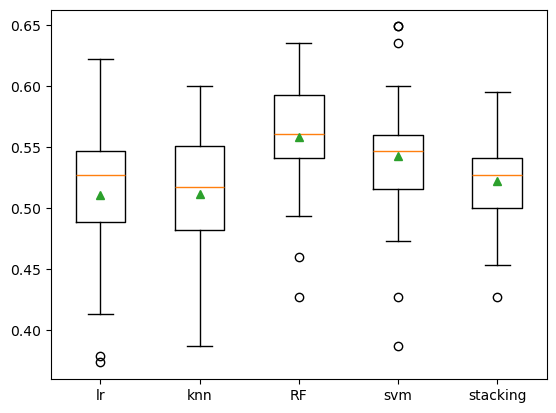

>lr 0.923 (0.040)
>knn 0.909 (0.064)
>RF 0.896 (0.050)
>svm 0.948 (0.044)
>stacking 0.932 (0.050)


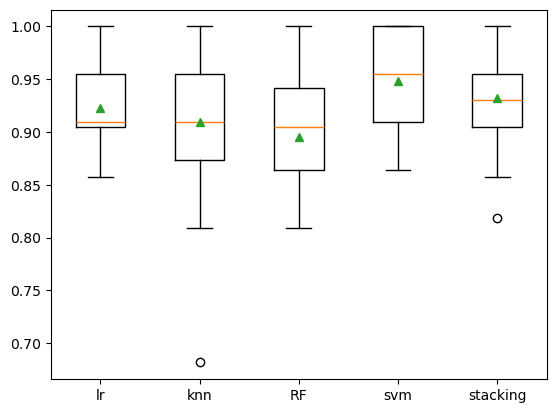

>lr 0.466 (0.086)
>knn 0.476 (0.099)
>RF 0.511 (0.088)
>svm 0.501 (0.084)
>stacking 0.487 (0.089)


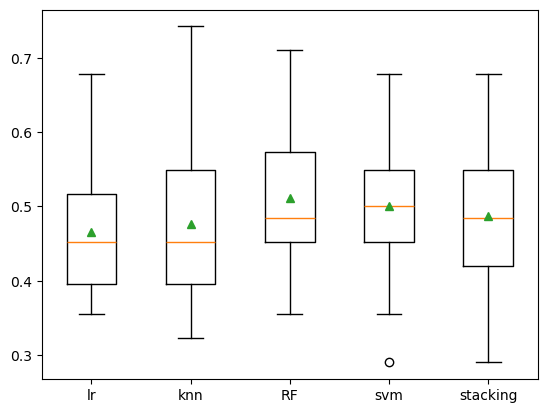

>lr 0.365 (0.060)
>knn 0.490 (0.057)
>RF 0.559 (0.052)
>svm 0.498 (0.058)
>stacking 0.543 (0.042)


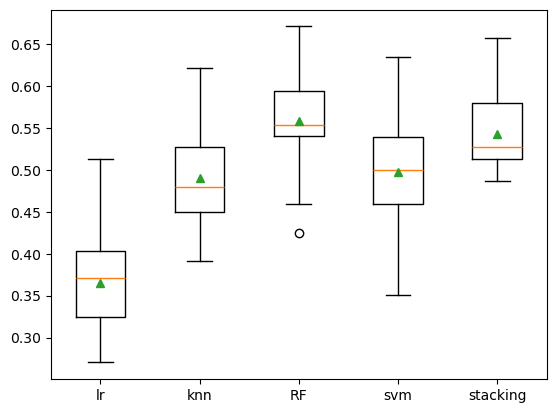

>lr 0.908 (0.057)
>knn 0.896 (0.063)
>RF 0.946 (0.043)
>svm 0.929 (0.049)
>stacking 0.948 (0.043)


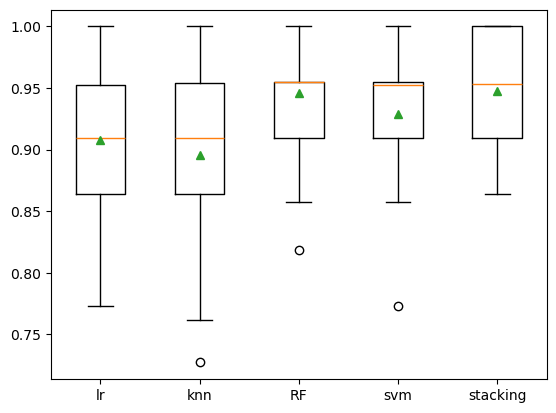

>lr 0.394 (0.081)
>knn 0.438 (0.082)
>RF 0.503 (0.089)
>svm 0.443 (0.065)
>stacking 0.449 (0.074)


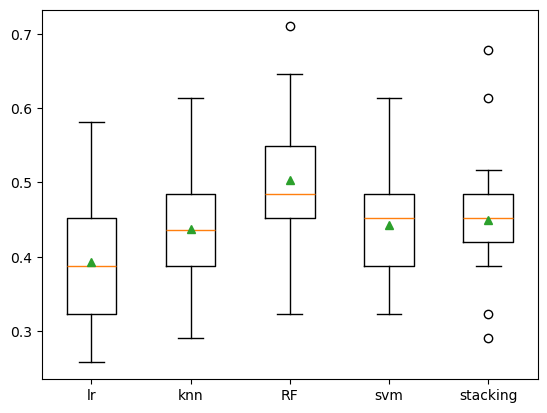

In [82]:
# First we can evaluate the performance of an assortment of classifiers to see how uncorrelated their performances are
# # I think this needs to be adapted pretty heavily to give each model a better chance - I'm not sure how much hyperparameter tuning is going on here

# Overall, this may be kind of a simplistic interpretation of a stacking classifier but it doesn't seem to be doing any better than the best classifier for any given dataset
# You can change StandardScaler to PoweverScaler and set PowerTransformer to Yeo-Johnson
def get_models():
    models = dict()
    models['lr'] = make_pipeline(StandardScaler(),
                                 LogisticRegression())
    models['knn'] = make_pipeline(StandardScaler(),
                                  PCA(),
                                  KNeighborsClassifier())
    models['RF'] = RandomForestClassifier()
    models['svm'] = make_pipeline(StandardScaler(),
                                #   PCA(),
                                  SVC())
    models['stacking'] = get_stacking()
    return models

def evaluate_model(model, X, y):
    cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
    scores = cross_val_score(model, X, y, scoring = 'accuracy', cv=cv, n_jobs=-1, error_score='raise')

    # cross_preds = cross_val_predict(model, X, y, cv=cv, n_jobs=-1)
    # conf_matrix = confusion_matrix(names, results)
    # ConfusionMatrixDisplay(conf_matrix)
    return {"scores": scores}
            # "cross_preds": cross_preds}

def get_stacking():
    # Define base models
    level0 = list()
    level0.append(('lr', make_pipeline(StandardScaler(),
                                 LogisticRegression(multi_class='multinomial'))))
    level0.append(('rf', RandomForestClassifier()))
    level0.append(('svm', make_pipeline(StandardScaler(),
                                  SVC())))
    level0.append(('knn', make_pipeline(StandardScaler(),
                                  KNeighborsClassifier())))

    # Define the meta learner model - here we leave the solver as 
    level1 = make_pipeline(StandardScaler(),
                           RandomForestClassifier())
                        #    LogisticRegression(multi_class='multinomial'))
    
    # Define the stacking ensemble
    model = StackingClassifier(estimators=level0, final_estimator=level1, cv=5)
    return model

def multiple_model_evaluator(X, y):
    models = get_models()
    results, names = list(), list()
    for name, model in models.items():
        evaluation = evaluate_model(model, X, y)
        # print(evaluation)
        eval_scores = evaluation["scores"]
        # cross_preds = evaluation[1]
        results.append(eval_scores)
        names.append(name)
        print('>%s %.3f (%.3f)' % (name, np.mean(eval_scores), np.std(eval_scores)))
        # print(cross_preds)

    plt.boxplot(results, labels=names, showmeans=True)
    plt.show()

    

multiple_model_evaluator(augmented_x, augmented_y)
multiple_model_evaluator(medium_trimmed_x, medium_trimmed_y)
multiple_model_evaluator(low_trimmed_x, low_trimmed_y)
multiple_model_evaluator(aug_total_norm_x, aug_total_norm_y)
multiple_model_evaluator(trim_aug_total_norm_x, trim_aug_total_norm_y)
multiple_model_evaluator(low_trim_aug_total_norm_x, low_trim_aug_total_norm_y)



In [ ]:
# Logistic regression and svm parameter tuning

In [ ]:
# Superlearner